In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# --------------------------------------------------
# 1. LOAD DATA FROM THE CSV
# --------------------------------------------------

df = pd.read_csv("breast-cancer-wisconsin-data.csv")

df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Malignant = 1 (positive)
# Benign = 0 (negative)
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print(df.shape)
print(df.head())

print("\nClass balance (1 = malignant):\n", df["diagnosis"].value_counts())
print("\nMissing values:", df.isnull().sum().sum())


(569, 31)
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38          122.80     1001.0   
1          1        20.57         17.77          132.90     1326.0   
2          1        19.69         21.25          130.00     1203.0   
3          1        11.42         20.38           77.58      386.1   
4          1        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0         0.2419  ...         25.38

In [11]:

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("Scalar", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Scalar', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [12]:
# Classification metrics need class labels; ROC-AUC uses probabilities.
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]



Confusion matrix:
 [[71  1]
 [ 3 39]]
TN=71  FP=1  FN=3  TP=39

Accuracy  : 0.9649
Precision : 0.975
Recall    : 0.9286
F1-score  : 0.9512
ROC-AUC   : 0.996

Full report:
               precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



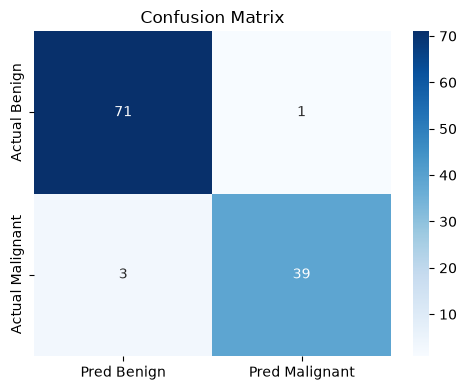


Top features:
                 feature      coef  abs_coef
21        texture_worst  1.434093  1.434093
10            radius_se  1.233325  1.233325
28       symmetry_worst  1.061264  1.061264
7   concave points_mean  0.952813  0.952813
26      concavity_worst  0.911406  0.911406
13              area_se  0.909029  0.909029
15       compactness_se -0.906925  0.906925
23           area_worst  0.900477  0.900477
20         radius_worst  0.896968  0.896968
6        concavity_mean  0.782298  0.782298


/tmp/ipykernel_41764/2913653090.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df.head(10), x="coef", y="feature", palette="coolwarm")


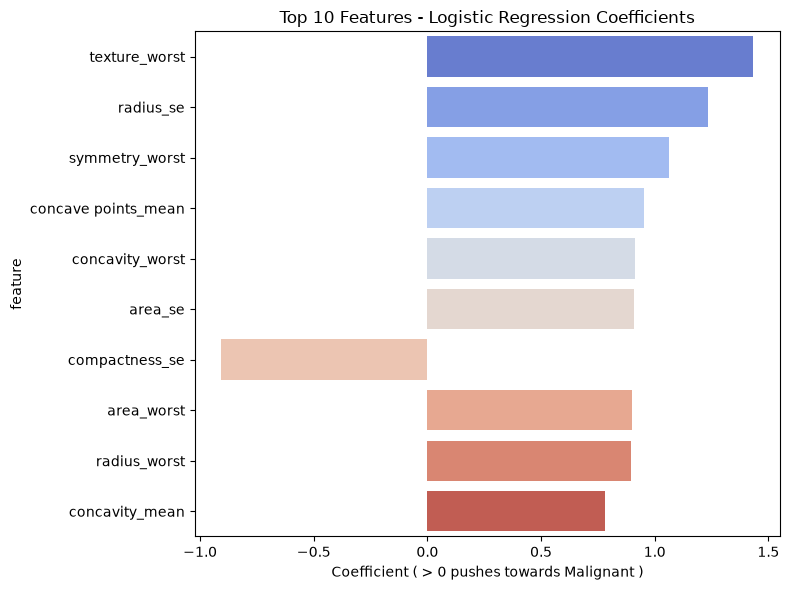

In [13]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("\nConfusion matrix:\n", cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

print("\nAccuracy  :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall    :", round(recall_score(y_test, y_pred), 4))
print("F1-score  :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC   :", round(roc_auc_score(y_test, y_prob), 4))

print("\nFull report:\n",
      classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Benign", "Pred Malignant"],
            yticklabels=["Actual Benign", "Actual Malignant"])
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# ------------------------------------------------------
# 6. INTERPRET: top features pushing towards malignant / benign
# ------------------------------------------------------
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coef": model.named_steps["logreg"].coef_[0]
})

coef_df["abs_coef"] = coef_df["coef"].abs()
coef_df = coef_df.sort_values("abs_coef", ascending=False)

print("\nTop features:\n", coef_df.head(10))

plt.figure(figsize=(8, 6))
sns.barplot(data=coef_df.head(10), x="coef", y="feature", palette="coolwarm")
plt.title("Top 10 Features - Logistic Regression Coefficients")
plt.xlabel("Coefficient ( > 0 pushes towards Malignant )")
plt.tight_layout()
plt.savefig("top_features.png")
plt.show()

In [14]:
# ------------------------------------------------------
# 7. THRESHOLD EXPERIMENT (precision / recall trade-off)
# ------------------------------------------------------
print("\nThreshold  Precision  Recall  F1")
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    print(f"{t:.1f}    {precision_score(y_test, pred_t, zero_division=0):.3f}    "
          f"{recall_score(y_test, pred_t):.3f}    "
          f"{f1_score(y_test, pred_t):.3f}")


Threshold  Precision  Recall  F1
0.1    0.891    0.976    0.932
0.3    0.976    0.976    0.976
0.5    0.975    0.929    0.951
0.7    1.000    0.905    0.950
0.9    1.000    0.786    0.880
